In [1]:
# ============ 셀 1: 설정 (E1: 평가 지표 확장) ============
import os, json, time, math, random, glob, shutil, copy
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.nn.attention import sdpa_kernel, SDPBackend

assert torch.cuda.is_available(), "GPU가 꺼져 있어요. Settings → Accelerator → GPU T4 로 바꾸세요."
DEV = 'cuda'

OUT  = '/kaggle/working/exp_e1'
DATA = '/tmp/llm_data'
os.makedirs(OUT, exist_ok=True); os.makedirs(DATA, exist_ok=True)

CFG = dict(
    seed=0, ctx=256, vocab=50304, d_model=512, n_layer=6, n_head=8, grad_clip=1.0,
    muon_momentum=0.95, ns_steps=5, muon_pre_lr=0.005,
    # 파인튜닝: L6B·L7과 완전히 동일 (재현 확인됨)
    ft_muon_div=[10, 3], ft_adam_lrs=[1e-4, 1e-3 / 3],
    ft_steps=1000, ft_bs=32, ft_wd=0.1, ft_warmup=50, ft_seeds=[0, 1, 2], ft_eval_every=100,
    code_files=10000, code_max_chars=20000, eval_seqs=400, eval_bs=32,
    # 평가 지표
    blimp_per_task=200,               # BLiMP 67개 현상 × 200쌍 = 13,400쌍
    quant_bits=[8, 4],
    noise_gammas=[0.01, 0.02, 0.05], noise_reps=3,
    hutch_samples=20, lam_batches=3, hvp_iters=20,
    curv_batches=2, cka_seqs=64, cka_tokens=4096,
)
json.dump(CFG, open(f'{OUT}/config.json', 'w'), indent=2)

# 이름: (입력 폴더, 파일, 사전학습 비용 배수)
MODELS = {
    'off':       ('exp_l6_pretrain', 'pre_off_repro.pt',          1.00),
    'decay0.02': ('exp_l6_pretrain', 'pre_decay_spec_0.02.pt',    1.26),
    'decay0.05': ('exp_l6_pretrain', 'pre_decay_spec_0.05.pt',    1.26),
    'full0.05':  ('exp_l7',          'pre_full_spec_0.05.pt',     2.27),
}

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def find_input(folder, name):
    hits = glob.glob(f'/kaggle/input/**/{folder}/{name}', recursive=True)
    assert hits, f"{folder}/{name}을 못 찾았어요. Add Input에서 해당 노트북을 추가했는지 확인하세요."
    return hits[0]

print('GPU :', torch.cuda.get_device_name(0), '| torch', torch.__version__)
for k, (folder, f, _) in MODELS.items():
    ok = glob.glob(f'/kaggle/input/**/{folder}/{f}', recursive=True)
    print(f'  입력 확인: {k:10s} {folder}/{f} →', '있음' if ok else '없음 ← Add Input 확인')

GPU : Tesla T4 | torch 2.11.0+cu128
  입력 확인: off        exp_l6_pretrain/pre_off_repro.pt → 있음
  입력 확인: decay0.02  exp_l6_pretrain/pre_decay_spec_0.02.pt → 있음
  입력 확인: decay0.05  exp_l6_pretrain/pre_decay_spec_0.05.pt → 있음
  입력 확인: full0.05   exp_l7/pre_full_spec_0.05.pt → 있음


In [2]:
# ============ 셀 2: BabyLM + 파이썬 코드 + BLiMP ============
from transformers import AutoTokenizer
from datasets import load_dataset
tok = AutoTokenizer.from_pretrained('gpt2'); tok.model_max_length = int(1e9)
EOS = tok.eos_token_id

def encode_texts(texts, bs=256):
    parts = []
    for i in range(0, len(texts), bs):
        for ids in tok(texts[i:i + bs])['input_ids']:
            parts.append(np.array(ids + [EOS], dtype=np.uint16))
    return np.concatenate(parts)

def chunk_lines(text, n=200):
    lines = text.split('\n')
    return ['\n'.join(lines[i:i + n]) for i in range(0, len(lines), n)]

# ---------- BabyLM (이전과 같은 방식) ----------
if not os.path.exists(f'{DATA}/babylm_val.npy'):
    try:
        from huggingface_hub import snapshot_download
        root = snapshot_download('cambridge-climb/BabyLM', repo_type='dataset', allow_patterns=['10M/*', 'dev/*'])
        tr_files = sorted(f for f in glob.glob(f'{root}/10M/*') if os.path.isfile(f))
        dv_files = sorted(f for f in glob.glob(f'{root}/dev/*') if os.path.isfile(f))
        assert tr_files and dv_files, '파일 없음'
        tr_texts, dv_texts = [], []
        for f in tr_files: tr_texts += chunk_lines(open(f, encoding='utf-8', errors='ignore').read())
        for f in dv_files: dv_texts += chunk_lines(open(f, encoding='utf-8', errors='ignore').read()[:500_000])
    except Exception as e:
        print('2023판 다운로드 실패 → 2026판으로 대체:', repr(e)[:120])
        ds = load_dataset('BabyLM-community/BabyLM-2026-Strict-Small', split='train')
        col = [c for c, t in ds.features.items() if getattr(t, 'dtype', None) == 'string'][0]
        lines = [t for t in ds[col] if t and t.strip()]
        idx = np.random.RandomState(0).permutation(len(lines)); nv = len(lines) // 20
        dv_lines = [lines[i] for i in idx[:nv]]; tr_lines = [lines[i] for i in idx[nv:]]
        tr_texts = ['\n'.join(tr_lines[i:i + 200]) for i in range(0, len(tr_lines), 200)]
        dv_texts = ['\n'.join(dv_lines[i:i + 200]) for i in range(0, len(dv_lines), 200)]
    tr = encode_texts(tr_texts); dv = encode_texts(dv_texts)
    np.save(f'{DATA}/babylm_train.npy', tr); np.save(f'{DATA}/babylm_val.npy', dv)
    print(f'BabyLM 토큰: train {len(tr)/1e6:.1f}M, val {len(dv)/1e6:.1f}M   (기존: 15.7M / 0.8M)')

# ---------- 파이썬 코드 (이전과 같은 방식) ----------
if not os.path.exists(f'{DATA}/code_val.npy'):
    try:
        ds = load_dataset('bigcode/the-stack-smol', data_dir='data/python', split='train')
    except Exception as e:
        print('the-stack-smol 실패 → codeparrot으로 대체:', repr(e)[:120])
        ds = load_dataset('codeparrot/codeparrot-clean-valid', split='train')
    n = min(CFG['code_files'], len(ds))
    ds = ds.shuffle(seed=0).select(range(n))
    files = [c[:CFG['code_max_chars']] for c in ds['content']]
    nv = n // 10
    cv = encode_texts(files[:nv]); ct = encode_texts(files[nv:])
    np.save(f'{DATA}/code_train.npy', ct); np.save(f'{DATA}/code_val.npy', cv)
    print(f'코드 토큰: train {len(ct)/1e6:.1f}M, val {len(cv)/1e6:.1f}M   (기존: 26.9M / 3.0M)')

# ---------- BLiMP (문법 능력 시험: 맞는 문장 vs 틀린 문장 중 맞는 쪽 확률이 높으면 정답) ----------
if not os.path.exists(f'{DATA}/blimp.json'):
    from datasets import get_dataset_config_names
    for name in ['nyu-mll/blimp', 'blimp']:
        try:
            cfgs = get_dataset_config_names(name); break
        except Exception as e:
            print(f'{name} 설정 목록 실패:', repr(e)[:120])
    rng = np.random.RandomState(0); rows = []
    for c in cfgs:
        ds = load_dataset(name, c, split='train')
        for i in rng.choice(len(ds), min(CFG['blimp_per_task'], len(ds)), replace=False):
            r = ds[int(i)]
            rows.append(dict(task=c, field=r.get('field', 'unknown'), good=r['sentence_good'], bad=r['sentence_bad']))
    json.dump(rows, open(f'{DATA}/blimp.json', 'w'))
BLIMP = json.load(open(f'{DATA}/blimp.json'))
print(f'BLiMP: {len(BLIMP)}쌍, 현상 {len(set(r["task"] for r in BLIMP))}개, 분야 {sorted(set(r["field"] for r in BLIMP))}')

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

wh_vs_that_with_gap_long_distance/train-(…): reconstructing file:   0%|          |  0.00B / 84.1kB            

wh_vs_that_with_gap_long_distance/train-(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

BLiMP: 13400쌍, 현상 67개, 분야 ['morphology', 'semantics', 'syntax', 'syntax/semantics', 'syntax_semantics']


In [3]:
# ============ 셀 3: 모델, Muon, 파인튜닝, 평가 지표 함수 ============
def load_tokens(name):
    return torch.from_numpy(np.load(f'{DATA}/{name}.npy').astype(np.int64)).to(DEV)

TR_BABY, VA_BABY = load_tokens('babylm_train'), load_tokens('babylm_val')
TR_CODE, VA_CODE = load_tokens('code_train'), load_tokens('code_val')

class Stream:
    def __init__(self, tokens, bs, ctx=CFG['ctx']):
        n = (len(tokens) - 1) // ctx
        self.chunks = tokens[:n * ctx + 1].unfold(0, ctx + 1, ctx)
        self.n, self.bs, self.spe = n, bs, n // bs
        self._key = None
    def batch(self, step, seed):
        ep, i = divmod(step, self.spe)
        if self._key != (seed, ep):
            g = torch.Generator().manual_seed(seed * 100003 + ep)
            self._perm = torch.randperm(self.n, generator=g).to(DEV); self._key = (seed, ep)
        b = self.chunks[self._perm[i * self.bs:(i + 1) * self.bs]]
        return b[:, :-1], b[:, 1:]

def make_eval(tokens, n, seed, ctx=CFG['ctx']):
    starts = np.random.RandomState(seed).randint(0, len(tokens) - ctx - 1, size=n)
    idx = torch.from_numpy(starts).to(DEV)[:, None] + torch.arange(ctx + 1, device=DEV)
    b = tokens[idx]
    return b[:, :-1], b[:, 1:]

EV_BABY = make_eval(VA_BABY, CFG['eval_seqs'], seed=11)    # 이전 실험들과 같은 평가 문장
EV_CODE = make_eval(VA_CODE, CFG['eval_seqs'], seed=12)

class Block(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.h = h
        self.ln1 = nn.LayerNorm(d); self.qkv = nn.Linear(d, 3 * d); self.proj = nn.Linear(d, d)
        self.ln2 = nn.LayerNorm(d); self.fc = nn.Linear(d, 4 * d); self.fc2 = nn.Linear(4 * d, d)
    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(self.ln1(x)).split(C, dim=2)
        q, k, v = [t.view(B, T, self.h, C // self.h).transpose(1, 2) for t in (q, k, v)]
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        x = x + self.proj(y.transpose(1, 2).contiguous().view(B, T, C))
        return x + self.fc2(F.gelu(self.fc(self.ln2(x))))

class GPT(nn.Module):
    def __init__(self, V=CFG['vocab'], d=CFG['d_model'], L=CFG['n_layer'], h=CFG['n_head'], T=CFG['ctx']):
        super().__init__()
        self.wte = nn.Embedding(V, d); self.wpe = nn.Embedding(T, d)
        self.blocks = nn.ModuleList([Block(d, h) for _ in range(L)])
        self.lnf = nn.LayerNorm(d)
    def forward(self, idx, targets=None, return_hidden=False):
        x = self.wte(idx) + self.wpe(torch.arange(idx.shape[1], device=idx.device))
        hs = [x] if return_hidden else None
        for b in self.blocks:
            x = b(x)
            if return_hidden: hs.append(x)
        logits = F.linear(self.lnf(x), self.wte.weight)
        if return_hidden: return logits, hs
        if targets is None: return logits
        return F.cross_entropy(logits.view(-1, logits.size(-1)), targets.reshape(-1))

def make_model():
    return GPT().to(DEV)

def load_model(sd):
    m = make_model(); m.load_state_dict(sd); return m

# ---------- Muon + 파인튜닝 (L6B·L7과 동일) ----------
def newton_schulz5(G, steps):
    a, b, c = 3.4445, -4.7750, 2.0315
    X = G.float(); X = X / (X.norm() + 1e-7)
    tr = X.size(0) > X.size(1)
    if tr: X = X.T
    for _ in range(steps):
        A = X @ X.T; B = b * A + c * (A @ A); X = a * X + B @ X
    return X.T if tr else X

class Muon(torch.optim.Optimizer):
    def __init__(self, params, lr=0.02, momentum=0.95, nesterov=True, ns_steps=5):
        super().__init__(params, dict(lr=lr, momentum=momentum, nesterov=nesterov, ns_steps=ns_steps))
    @torch.no_grad()
    def step(self, closure=None):
        for grp in self.param_groups:
            for p in grp['params']:
                if p.grad is None: continue
                st = self.state[p]
                if 'buf' not in st: st['buf'] = torch.zeros_like(p.grad)
                buf = st['buf']; buf.mul_(grp['momentum']).add_(p.grad)
                u = p.grad.add(buf, alpha=grp['momentum']) if grp['nesterov'] else buf
                u = newton_schulz5(u, grp['ns_steps'])
                u *= max(1.0, p.size(0) / p.size(1)) ** 0.5
                p.add_(u.to(p.dtype), alpha=-grp['lr'])

def make_muon_opts(model, muon_lr, adam_lr, wd):
    hidden = [p for p in model.blocks.parameters() if p.ndim == 2]
    hid = {id(p) for p in hidden}
    rest = [p for p in model.parameters() if id(p) not in hid]
    muon = Muon(hidden, lr=muon_lr, momentum=CFG['muon_momentum'], ns_steps=CFG['ns_steps'])
    adam = torch.optim.AdamW([{'params': [p for p in rest if p.ndim >= 2], 'weight_decay': wd},
                              {'params': [p for p in rest if p.ndim < 2], 'weight_decay': 0.0}],
                             lr=adam_lr, betas=(0.9, 0.95), eps=1e-8)
    for o, lr in ((muon, muon_lr), (adam, adam_lr)):
        for g in o.param_groups: g['base_lr'] = lr
    return [muon, adam]

def cos_fn(total, warm):
    def f(s):
        if s < warm: return (s + 1) / warm
        return 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm)))
    return f

def train_step(model, opts, scaler, x, y):
    with torch.autocast('cuda', dtype=torch.float16):
        loss = model(x, y)
    model.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    for o in opts: scaler.unscale_(o)
    torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
    for o in opts: scaler.step(o)
    scaler.update()

# ---------- 기본 평가 ----------
@torch.no_grad()
def eval_loss(model, ev):
    model.eval(); X, Y = ev; tot = 0.0; bs = CFG['eval_bs']
    for i in range(0, len(X), bs):
        with torch.autocast('cuda', dtype=torch.float16):
            tot += model(X[i:i + bs], Y[i:i + bs]).float().item() * len(X[i:i + bs])
    model.train()
    return tot / len(X)

@torch.no_grad()
def token_acc(model, ev):
    """다음 토큰 정확도 (가장 확률 높은 토큰이 정답인 비율)"""
    model.eval(); X, Y = ev; hit = 0; n = 0; bs = CFG['eval_bs']
    for i in range(0, len(X), bs):
        with torch.autocast('cuda', dtype=torch.float16):
            pred = model(X[i:i + bs]).argmax(-1)
        hit += (pred == Y[i:i + bs]).sum().item(); n += Y[i:i + bs].numel()
    model.train()
    return hit / n

# ---------- BLiMP ----------
_ids = lambda s: [EOS] + tok(s)['input_ids']
BL_GOOD = [_ids(r['good']) for r in BLIMP]; BL_BAD = [_ids(r['bad']) for r in BLIMP]
BL_FIELD = np.array([r['field'] for r in BLIMP])

@torch.no_grad()
def sent_logprob(model, seqs, bs=128):
    model.eval(); out = np.zeros(len(seqs)); order = np.argsort([len(s) for s in seqs])
    for i in range(0, len(seqs), bs):
        idx = order[i:i + bs]; L = max(len(seqs[j]) for j in idx)
        X = torch.full((len(idx), L), EOS, dtype=torch.long, device=DEV); M = torch.zeros((len(idx), L), device=DEV)
        for r, j in enumerate(idx):
            X[r, :len(seqs[j])] = torch.tensor(seqs[j], device=DEV); M[r, :len(seqs[j])] = 1
        with torch.autocast('cuda', dtype=torch.float16):
            logits = model(X[:, :-1])
        lp = torch.log_softmax(logits.float(), -1).gather(-1, X[:, 1:, None]).squeeze(-1) * M[:, 1:]
        out[idx] = lp.sum(1).cpu().numpy()
    model.train()
    return out

def blimp(model):
    ok = sent_logprob(model, BL_GOOD) > sent_logprob(model, BL_BAD)
    return dict(acc=float(ok.mean()), **{f'acc_{f}': float(ok[BL_FIELD == f].mean()) for f in sorted(set(BL_FIELD))})

# ---------- 강건성 ----------
@torch.no_grad()
def quantized(model, bits):
    """채널별 대칭 반올림 양자화(RTN) 후 다시 실수로 되돌린 복사본"""
    m = copy.deepcopy(model); qmax = 2 ** (bits - 1) - 1
    for p in m.parameters():
        if p.ndim == 2:
            s = p.abs().amax(dim=1, keepdim=True).clamp(min=1e-8) / qmax
            p.copy_((p / s).round().clamp(-qmax - 1, qmax) * s)
    return m

def quant_metrics(model, base_baby, base_code):
    out = {}
    for b in CFG['quant_bits']:
        q = quantized(model, b)
        out[f'int{b}_baby_inc'] = eval_loss(q, EV_BABY) - base_baby
        out[f'int{b}_code_inc'] = eval_loss(q, EV_CODE) - base_code
        del q
    torch.cuda.empty_cache()
    return out

@torch.no_grad()
def noise_metrics(model, base_baby):
    """행렬마다 RMS의 γ배 크기 가우시안 잡음 → BabyLM loss 증가 (잡음 seed 평균)"""
    mats = [p for p in model.parameters() if p.ndim == 2]; out = {}
    for g in CFG['noise_gammas']:
        vals = []
        for r in range(CFG['noise_reps']):
            gen = torch.Generator(device=DEV).manual_seed(1000 + r)
            backup = [p.detach().clone() for p in mats]
            for p in mats:
                p.add_(torch.randn(p.shape, generator=gen, device=DEV) * g * p.norm() / math.sqrt(p.numel()))
            vals.append(eval_loss(model, EV_BABY) - base_baby)
            for p, b in zip(mats, backup): p.copy_(b)
        out[f'noise{g:g}_inc'] = float(np.mean(vals))
    return out

# ---------- 곡률 ----------
def lambda_max(model, batch, iters):
    model.eval(); x, y = batch; params = list(model.parameters())
    with sdpa_kernel(SDPBackend.MATH):
        loss = model(x, y)
        grads = torch.autograd.grad(loss, params, create_graph=True)
        v = [torch.randn_like(p) for p in params]
        nrm = torch.sqrt(sum((a * a).sum() for a in v)); v = [a / nrm for a in v]
        lam = 0.0
        for _ in range(iters):
            Hv = torch.autograd.grad(grads, params, grad_outputs=v, retain_graph=True)
            lam = sum((h * a).sum() for h, a in zip(Hv, v)).item()
            nrm = torch.sqrt(sum((h * h).sum() for h in Hv)); v = [h.detach() / nrm for h in Hv]
    del grads
    return lam

def hutchinson_trace(model, batches, n):
    """Hessian의 대각합(평균 곡률) 추정"""
    model.eval(); params = list(model.parameters()); vals = []
    with sdpa_kernel(SDPBackend.MATH):
        for k in range(n):
            x, y = batches[k % len(batches)]
            loss = model(x, y)
            grads = torch.autograd.grad(loss, params, create_graph=True)
            v = [torch.randint_like(p, 2) * 2 - 1 for p in params]
            Hv = torch.autograd.grad(grads, params, grad_outputs=v)
            vals.append(sum((h * a).sum() for h, a in zip(Hv, v)).item())
            del grads, Hv
    return float(np.mean(vals)), float(np.std(vals) / math.sqrt(n))

@torch.no_grad()
def rank_metrics(model):
    er, sr = [], []
    for p in model.blocks.parameters():
        if p.ndim == 2:
            s = torch.linalg.svdvals(p.float()); q = s / s.sum()
            er.append((torch.exp(-(q * torch.log(q + 1e-12)).sum()) / len(s)).item())
            sr.append((s.pow(2).sum() / s[0] ** 2).item())
    return dict(erank_norm=float(np.mean(er)), stable_rank=float(np.mean(sr)))

def dir_curvature(sd_pre, sd_post, batches):
    """파인튜닝 이동 Δ 방향에서 원래 과제(BabyLM)의 1차·2차 항 vs 실제 loss 증가"""
    m = load_model(sd_pre); m.eval(); names = [n for n, _ in m.named_parameters()]
    params = [p for _, p in m.named_parameters()]
    delta = [(sd_post[n].float() - p.detach().float()) for n, p in zip(names, params)]
    dn2 = sum((d * d).sum() for d in delta).item()
    mp = load_model(sd_post); mp.eval(); g1, q2, act = [], [], []
    with sdpa_kernel(SDPBackend.MATH):
        for x, y in batches:
            loss = m(x, y)
            grads = torch.autograd.grad(loss, params, create_graph=True)
            gd = sum((g * d).sum() for g, d in zip(grads, delta))
            Hd = torch.autograd.grad(gd, params)
            dHd = sum((h * d).sum() for h, d in zip(Hd, delta)).item()
            with torch.no_grad():
                act.append((mp(x, y) - loss).item())
            g1.append(gd.item()); q2.append(dHd)
            del grads, Hd
    del m, mp; torch.cuda.empty_cache()
    return dict(dir_curv=float(np.mean(q2)) / dn2, first_order=float(np.mean(g1)),
                second_order=0.5 * float(np.mean(q2)), quad_pred=float(np.mean(g1)) + 0.5 * float(np.mean(q2)),
                actual_inc=float(np.mean(act)))

# ---------- 층별 표현 유사도 (CKA) ----------
CKA_X = EV_BABY[0][:CFG['cka_seqs']]
CKA_IDX = torch.from_numpy(np.random.RandomState(7).choice(CKA_X.numel(), CFG['cka_tokens'], replace=False)).to(DEV)

@torch.no_grad()
def layer_feats(model):
    model.eval(); outs = None
    for i in range(0, len(CKA_X), 16):
        with torch.autocast('cuda', dtype=torch.float16):
            _, hs = model(CKA_X[i:i + 16], return_hidden=True)
        hs = [h.float().reshape(-1, h.size(-1)) for h in hs]
        outs = hs if outs is None else [torch.cat([a, b]) for a, b in zip(outs, hs)]
    return [h[CKA_IDX].double() for h in outs]

def linear_cka(A, B):
    A = A - A.mean(0); B = B - B.mean(0)
    return ((A.T @ B).norm() ** 2 / ((A.T @ A).norm() * (B.T @ B).norm())).item()

def delta_rel(sd_a, sd_b):
    num = den = 0.0
    for k, v in sd_a.items():
        if not v.is_floating_point(): continue
        num += (sd_b[k].float() - v.float()).pow(2).sum().item(); den += v.float().pow(2).sum().item()
    return math.sqrt(num / den)

def baby_at(curve, target):
    for a, b in zip(curve, curve[1:]):
        if b['code'] <= target:
            t = 1.0 if a['code'] == b['code'] else min(max((a['code'] - target) / (a['code'] - b['code']), 0), 1)
            return a['baby'] + t * (b['baby'] - a['baby'])
    return float('nan')

tr_stream = Stream(TR_BABY, 32)
SHARP_BATCHES = [tuple(t[:16] for t in tr_stream.batch(s, seed=999)) for s in range(max(CFG['lam_batches'], 4))]
CURV_BATCHES = SHARP_BATCHES[:CFG['curv_batches']]
print('도구 준비 완료')

도구 준비 완료


In [4]:
# ============ 셀 4: 사전학습 직후 지표 ============
PRE_SD = {k: torch.load(find_input(folder, f), map_location=DEV) for k, (folder, f, _) in MODELS.items()}
pre_path = f'{OUT}/pretrain_metrics.json'
PRE = json.load(open(pre_path)) if os.path.exists(pre_path) else {}
PRE_FEATS = {}

for k, sd in PRE_SD.items():
    m = load_model(sd)
    PRE_FEATS[k] = layer_feats(m)
    if k in PRE:
        print(k, '이미 측정됨 → 건너뜀'); del m; continue
    t0 = time.time()
    r = dict(cost=MODELS[k][2])
    r['baby_loss'] = eval_loss(m, EV_BABY); r['code_loss'] = eval_loss(m, EV_CODE)
    r['baby_acc'] = token_acc(m, EV_BABY); r['code_acc'] = token_acc(m, EV_CODE)
    r.update({f'blimp_{a}': v for a, v in blimp(m).items()})
    r.update(quant_metrics(m, r['baby_loss'], r['code_loss']))
    r.update(noise_metrics(m, r['baby_loss']))
    r['hess_trace'], r['hess_trace_se'] = hutchinson_trace(m, SHARP_BATCHES, CFG['hutch_samples'])
    lams = [lambda_max(m, b, CFG['hvp_iters']) for b in SHARP_BATCHES[:CFG['lam_batches']]]
    r['lambda_max'], r['lambda_max_sd'] = float(np.mean(lams)), float(np.std(lams))
    r.update(rank_metrics(m))
    PRE[k] = r; json.dump(PRE, open(pre_path, 'w'), indent=2)
    print(f'{k:10s} BabyLM {r["baby_loss"]:.4f} | BLiMP {r["blimp_acc"]*100:.2f}% | INT4 +{r["int4_baby_inc"]:.4f} | '
          f'노이즈0.02 +{r["noise0.02_inc"]:.4f} | trace {r["hess_trace"]:.1f} | λmax {r["lambda_max"]:.1f}±{r["lambda_max_sd"]:.1f} | '
          f'{time.time()-t0:.0f}s', flush=True)
    del m; torch.cuda.empty_cache()

pre_df = pd.DataFrame(PRE).T
print('\n===== 사전학습 직후 =====')
display(pre_df[['cost', 'baby_loss', 'baby_acc', 'code_loss', 'blimp_acc', 'int8_baby_inc', 'int4_baby_inc',
                'noise0.01_inc', 'noise0.02_inc', 'noise0.05_inc', 'hess_trace', 'lambda_max', 'lambda_max_sd',
                'erank_norm', 'stable_rank']].astype(float).round(4))

off        BabyLM 3.3800 | BLiMP 66.19% | INT4 +0.9468 | 노이즈0.02 +0.0155 | trace 9471.5 | λmax 131.4±8.5 | 94s
decay0.02  BabyLM 3.2299 | BLiMP 68.18% | INT4 +0.4172 | 노이즈0.02 +0.0098 | trace 3982.9 | λmax 59.2±3.8 | 111s
decay0.05  BabyLM 3.2429 | BLiMP 68.31% | INT4 +0.3306 | 노이즈0.02 +0.0068 | trace 2403.6 | λmax 40.8±2.6 | 111s
full0.05   BabyLM 3.2725 | BLiMP 68.28% | INT4 +0.1694 | 노이즈0.02 +0.0054 | trace 824.1 | λmax 17.7±1.1 | 111s

===== 사전학습 직후 =====


,cost,baby_loss,baby_acc,code_loss,blimp_acc,int8_baby_inc,int4_baby_inc,noise0.01_inc,noise0.02_inc,noise0.05_inc,hess_trace,lambda_max,lambda_max_sd,erank_norm,stable_rank
off,1.00,3.3800,0.4253,7.7164,0.6619,0.0013,0.9468,0.0039,0.0155,0.0977,9471.5111,131.4048,8.4738,0.9047,128.4011
decay0.02,1.26,3.2299,0.4340,6.9060,0.6818,0.0007,0.4172,0.0024,0.0098,0.0631,3982.9203,59.2129,3.8407,0.8884,120.2032
decay0.05,1.26,3.2429,0.4291,6.6459,0.6831,0.0004,0.3306,0.0017,0.0068,0.0430,2403.6388,40.7781,2.6242,0.8703,109.6110
full0.05,2.27,3.2725,0.4265,6.7105,0.6828,0.0002,0.1694,0.0012,0.0054,0.0356,824.1109,17.7030,1.1465,0.8307,90.1917


In [5]:
# ============ 셀 5: Muon 파인튜닝 (4모델 × 약/강 × seed 3 = 24회) + 파인튜닝 후 지표 ============
FT_SETTINGS = [(CFG['muon_pre_lr'] / d, a) for d, a in zip(CFG['ft_muon_div'], CFG['ft_adam_lrs'])]
STRENGTH = {round(a, 12): s for (_, a), s in zip(FT_SETTINGS, ['weak', 'strong'])}
code_stream = Stream(TR_CODE, CFG['ft_bs'])
ft_lr_fn = cos_fn(CFG['ft_steps'], CFG['ft_warmup'])

res_path, curve_path, cka_path = f'{OUT}/ft_results.csv', f'{OUT}/ft_curves.json', f'{OUT}/ft_cka.json'
ROWS = pd.read_csv(res_path).to_dict('records') if os.path.exists(res_path) else []
CURVES = json.load(open(curve_path)) if os.path.exists(curve_path) else {}
CKA = json.load(open(cka_path)) if os.path.exists(cka_path) else {}
done = {(r['strength'], r['seed'], r['model']) for r in ROWS}

total = len(FT_SETTINGS) * len(CFG['ft_seeds']) * len(MODELS); k = 0; t_all = time.time()
for muon_lr, adam_lr in FT_SETTINGS:
    st = STRENGTH[round(adam_lr, 12)]
    for s in CFG['ft_seeds']:
        for key in MODELS:
            k += 1
            if (st, s, key) in done: continue
            t0 = time.time()
            seed_all(s)
            model = load_model(PRE_SD[key])
            opts = make_muon_opts(model, muon_lr, adam_lr, CFG['ft_wd']); scaler = torch.amp.GradScaler('cuda')
            curve = [dict(step=0, code=eval_loss(model, EV_CODE), baby=eval_loss(model, EV_BABY))]
            model.train()
            for stp in range(CFG['ft_steps']):
                f = ft_lr_fn(stp)
                for o in opts:
                    for g in o.param_groups: g['lr'] = g['base_lr'] * f
                x, y = code_stream.batch(stp, s)
                train_step(model, opts, scaler, x, y)
                if (stp + 1) % CFG['ft_eval_every'] == 0:
                    curve.append(dict(step=stp + 1, code=eval_loss(model, EV_CODE), baby=eval_loss(model, EV_BABY)))
            t_ft = time.time() - t0
            # ----- 파인튜닝 후 지표 -----
            sd_post = {n: v.detach().clone() for n, v in model.state_dict().items()}
            P = PRE[key]; c0, cN = curve[0], curve[-1]
            row = dict(strength=st, seed=s, model=key, cost=MODELS[key][2],
                       code_after=cN['code'], baby_before=c0['baby'], baby_after=cN['baby'], forgetting=cN['baby'] - c0['baby'],
                       code_acc_after=token_acc(model, EV_CODE), baby_acc_after=token_acc(model, EV_BABY))
            row['baby_acc_drop'] = P['baby_acc'] - row['baby_acc_after']
            bl = blimp(model); row['blimp_after'] = bl['acc']; row['blimp_drop'] = P['blimp_acc'] - bl['acc']
            for f_ in sorted(set(BL_FIELD)): row[f'blimp_drop_{f_}'] = P[f'blimp_acc_{f_}'] - bl[f'acc_{f_}']
            q = quant_metrics(model, cN['baby'], cN['code'])
            row['ft_int4_baby_inc'], row['ft_int4_code_inc'] = q['int4_baby_inc'], q['int4_code_inc']
            row['delta_rel'] = delta_rel(PRE_SD[key], sd_post)
            row.update(dir_curvature(PRE_SD[key], sd_post, CURV_BATCHES))
            feats = layer_feats(model)
            CKA[f'{st}|{s}|{key}'] = [linear_cka(a, b) for a, b in zip(PRE_FEATS[key], feats)]
            row['cka_last'] = CKA[f'{st}|{s}|{key}'][-1]
            ROWS.append(row); CURVES[f'{st}|{s}|{key}'] = curve
            pd.DataFrame(ROWS).to_csv(res_path, index=False)
            json.dump(CURVES, open(curve_path, 'w')); json.dump(CKA, open(cka_path, 'w'))
            print(f'[{k:2d}/{total}] {st:6s} seed={s} {key:10s} | 코드 {cN["code"]:.3f} | 망각 +{row["forgetting"]:.4f} | '
                  f'BLiMP {P["blimp_acc"]*100:.1f}→{bl["acc"]*100:.1f}% | 방향곡률 {row["dir_curv"]:.3f} | '
                  f'예측 {row["quad_pred"]:.3f} vs 실제 {row["actual_inc"]:.3f} | CKA끝 {row["cka_last"]:.3f} | '
                  f'학습 {t_ft:.0f}s + 측정 {time.time()-t0-t_ft:.0f}s (누적 {(time.time()-t_all)/60:.0f}분)', flush=True)
            del model, opts, sd_post; torch.cuda.empty_cache()
print('\n파인튜닝 + 측정 완료')

[ 1/24] weak   seed=0 off        | 코드 3.072 | 망각 +1.0164 | BLiMP 66.2→64.4% | 방향곡률 0.000 | 예측 1.073 vs 실제 1.494 | CKA끝 0.687 | 학습 335s + 측정 15s (누적 6분)
[ 2/24] weak   seed=0 decay0.02  | 코드 3.043 | 망각 +0.8928 | BLiMP 68.2→65.2% | 방향곡률 0.000 | 예측 0.575 vs 실제 1.056 | CKA끝 0.744 | 학습 337s + 측정 15s (누적 12분)
[ 3/24] weak   seed=0 decay0.05  | 코드 3.078 | 망각 +0.7985 | BLiMP 68.3→65.4% | 방향곡률 0.000 | 예측 0.419 vs 실제 0.840 | CKA끝 0.781 | 학습 337s + 측정 15s (누적 18분)
[ 4/24] weak   seed=0 full0.05   | 코드 3.316 | 망각 +0.6254 | BLiMP 68.3→66.0% | 방향곡률 0.000 | 예측 0.319 vs 실제 0.668 | CKA끝 0.811 | 학습 340s + 측정 15s (누적 23분)
[ 5/24] weak   seed=1 off        | 코드 3.076 | 망각 +1.0278 | BLiMP 66.2→64.4% | 방향곡률 0.000 | 예측 1.076 vs 실제 1.505 | CKA끝 0.686 | 학습 336s + 측정 15s (누적 29분)
[ 6/24] weak   seed=1 decay0.02  | 코드 3.046 | 망각 +0.9096 | BLiMP 68.2→65.2% | 방향곡률 0.000 | 예측 0.573 vs 실제 1.071 | CKA끝 0.733 | 학습 337s + 측정 15s (누적 35분)
[ 7/24] weak   seed=1 decay0.05  | 코드 3.079 | 망각 +0.8100 | BLiMP 68.3→65.4% | 방향곡률 

재현 확인 — off 망각 (L6B·L7 기록: 약 1.0204 / 강 1.7459): {'weak': np.float64(1.0204), 'strong': np.float64(1.746)}

===== 파인튜닝 후 (seed 3개 평균) | 같은 지점 기준: 약 3.321, 강 2.722 =====


code_after  code_acc_after  forgetting  \
strength model                                               
weak     off            3.0756          0.5370      1.0204   
         decay0.02      3.0459          0.5401      0.8993   
         decay0.05      3.0796          0.5354      0.8053   
         full0.05       3.3180          0.5054      0.6197   
strong   off            2.5377          0.6002      1.7460   
         decay0.02      2.5132          0.6032      1.6115   
         decay0.05      2.5144          0.6030      1.4213   
         full0.05       2.7194          0.5773      1.2806   

                    matched_forgetting  baby_acc_drop  blimp_after  \
strength model                                                       
weak     off                    0.8617         0.1019       0.6417   
         decay0.02              0.6792         0.0891       0.6513   
         decay0.05              0.6262         0.0801       0.6527   
         full0.05               0.6177         0.0670       0.6610   
strong   off                    1.5707         0.1553       0.5956   
         decay0.02              1.3537         0.1483       0.6117   
         decay0.05              1.1957         0.1219       0.6149   
         full0.05               1.2737         0.1117       0.6341   

                    blimp_drop  ft_int4_baby_inc  delta_rel  dir_curv  \
strength model                                                          
weak     off            0.0201            3.1034     0.1053    0.0002   
         decay0.02      0.0305            1.8284     0.1223    0.0001   
         decay0.05      0.0303            1.9266     0.1360    0.0001   
         full0.05       0.0218            0.5089     0.0989    0.0000   
strong   off            0.0662            4.2619     0.2075    0.0001   
         decay0.02      0.0700            2.1270     0.2318    0.0001   
         decay0.05      0.0682            2.8958     0.2587    0.0000   
         full0.05       0.0486            0.9016     0.1985    0.0000   

                    first_order  second_order  quad_pred  actual_inc  cka_last  
strength model                                                                  
weak     off             0.0781        0.9934     1.0715      1.4959    0.6884  
         decay0.02       0.0330        0.5415     0.5745      1.0610    0.7400  
         decay0.05      -0.0199        0.4387     0.4188      0.8474    0.7787  
         full0.05        0.0000        0.3190     0.3190      0.6626    0.8126  
strong   off             0.1726        2.2528     2.4254      2.3830    0.5543  
         decay0.02       0.1039        1.4074     1.5112      1.8706    0.6568  
         decay0.05       0.0064        1.2219     1.2283      1.5059    0.6995  
         full0.05        0.0281        0.6965     0.7246      1.3647    0.6534


===== off 대비 (같은 seed 짝 비교, 양수 = 더 좋음) =====

[weak]
  decay0.02  | forgetting +11.9% (3/3) | matched_forgetting +21.2% (3/3) | baby_acc_drop +0.0128 (3/3) | blimp_drop -0.0104 (0/3) | ft_int4_baby_inc +1.2750 (3/3) | code_after +0.0297 (3/3)
  decay0.05  | forgetting +21.1% (3/3) | matched_forgetting +27.3% (3/3) | baby_acc_drop +0.0218 (3/3) | blimp_drop -0.0102 (0/3) | ft_int4_baby_inc +1.1768 (3/3) | code_after -0.0040 (0/3)
  full0.05   | forgetting +39.3% (3/3) | matched_forgetting +28.3% (3/3) | baby_acc_drop +0.0349 (3/3) | blimp_drop -0.0017 (1/3) | ft_int4_baby_inc +2.5945 (3/3) | code_after -0.2423 (0/3)

[strong]
  decay0.02  | forgetting +7.7% (3/3) | matched_forgetting +13.8% (3/3) | baby_acc_drop +0.0071 (3/3) | blimp_drop -0.0038 (0/3) | ft_int4_baby_inc +2.1349 (3/3) | code_after +0.0245 (3/3)
  decay0.05  | forgetting +18.6% (3/3) | matched_forgetting +23.9% (3/3) | baby_acc_drop +0.0334 (3/3) | blimp_drop -0.0019 (1/3) | ft_int4_baby_inc +1.3661 (3/3) | code_after +

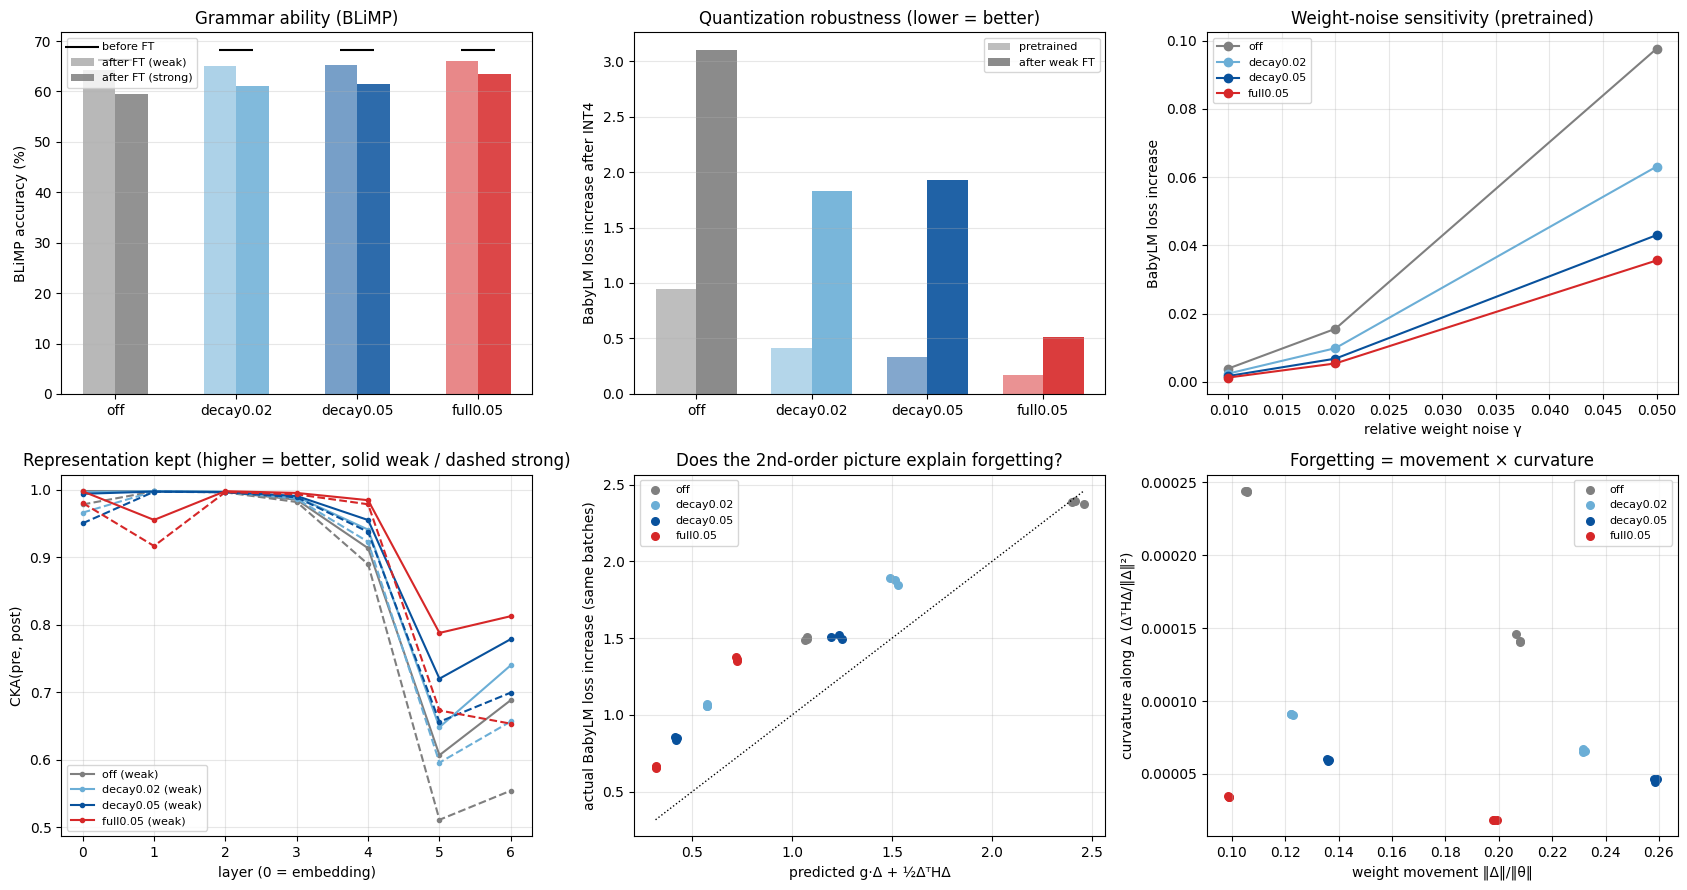

저장: /kaggle/working/exp_e1


In [6]:
# ============ 셀 6: 결과 정리 ============
import matplotlib.pyplot as plt
df = pd.DataFrame(ROWS)
KEYS = list(MODELS)
print('재현 확인 — off 망각 (L6B·L7 기록: 약 1.0204 / 강 1.7459):',
      {st: round(df[(df.strength == st) & (df.model == 'off')].forgetting.mean(), 4) for st in ['weak', 'strong']})

# 같은 지점 망각 (이 노트북 4모델 × seed 3이 모두 도달한 코드 loss)
TARGET = {}; df['matched_forgetting'] = np.nan
for st in ['weak', 'strong']:
    sub = df[df.strength == st]
    TARGET[st] = max(min(p['code'] for p in CURVES[f'{st}|{r.seed}|{r.model}']) for r in sub.itertuples())
    for i, r in sub.iterrows():
        df.loc[i, 'matched_forgetting'] = baby_at(CURVES[f'{st}|{r.seed}|{r.model}'], TARGET[st]) - r.baby_before
df.to_csv(f'{OUT}/ft_results_final.csv', index=False)

COLS = ['code_after', 'code_acc_after', 'forgetting', 'matched_forgetting', 'baby_acc_drop', 'blimp_after', 'blimp_drop',
        'ft_int4_baby_inc', 'delta_rel', 'dir_curv', 'first_order', 'second_order', 'quad_pred', 'actual_inc', 'cka_last']
print(f'\n===== 파인튜닝 후 (seed 3개 평균) | 같은 지점 기준: 약 {TARGET["weak"]:.3f}, 강 {TARGET["strong"]:.3f} =====')
display(df.groupby(['strength', 'model'], sort=False)[COLS].mean().round(4))

print('\n===== off 대비 (같은 seed 짝 비교, 양수 = 더 좋음) =====')
better_if_lower = ['forgetting', 'matched_forgetting', 'baby_acc_drop', 'blimp_drop', 'ft_int4_baby_inc', 'code_after']
for st in ['weak', 'strong']:
    a = df[(df.strength == st) & (df.model == 'off')].set_index('seed').sort_index()
    print(f'\n[{st}]')
    for key in KEYS[1:]:
        b = df[(df.strength == st) & (df.model == key)].set_index('seed').sort_index()
        parts = []
        for c in better_if_lower:
            d = a[c] - b[c]
            rel = f'{(1 - b[c].mean() / a[c].mean())*100:+.1f}%' if c in ['forgetting', 'matched_forgetting'] else f'{d.mean():+.4f}'
            parts.append(f'{c} {rel} ({int((d > 0).sum())}/3)')
        print(f'  {key:10s} | ' + ' | '.join(parts))

pre_df = pd.DataFrame(PRE).T.astype(float)
summary = dict(target=TARGET, pretrain=PRE,
               finetune=df.groupby(['strength', 'model'])[COLS].mean().reset_index().to_dict('records'))
json.dump(summary, open(f'{OUT}/summary.json', 'w'), indent=2, default=float)

# ---------- 그림 ----------
colors = dict(zip(KEYS, ['tab:gray', '#6baed6', '#08519c', 'tab:red']))
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
x = np.arange(len(KEYS))
ax = axes[0, 0]   # BLiMP
for j, st in enumerate(['weak', 'strong']):
    m = df[df.strength == st].groupby('model').blimp_after.mean().reindex(KEYS) * 100
    ax.bar(x + (j - 0.5) * 0.27, m, 0.27, label=f'after FT ({st})', alpha=0.85 if j else 0.55, color=[colors[k] for k in KEYS])
ax.scatter(x, pre_df.loc[KEYS, 'blimp_acc'] * 100, color='k', marker='_', s=600, zorder=3, label='before FT')
ax.set_xticks(x); ax.set_xticklabels(KEYS); ax.set_ylabel('BLiMP accuracy (%)'); ax.set_title('Grammar ability (BLiMP)')
ax.legend(fontsize=8); ax.grid(alpha=0.3, axis='y')
ax = axes[0, 1]   # 양자화
for j, (col, src, lab) in enumerate([('int4_baby_inc', pre_df.loc[KEYS], 'pretrained'),
                                      ('ft_int4_baby_inc', df[df.strength == 'weak'].groupby('model').mean(numeric_only=True).reindex(KEYS), 'after weak FT')]):
    ax.bar(x + (j - 0.5) * 0.35, src[col], 0.35, label=lab, color=[colors[k] for k in KEYS], alpha=0.5 + 0.4 * j)
ax.set_xticks(x); ax.set_xticklabels(KEYS); ax.set_ylabel('BabyLM loss increase after INT4'); ax.set_title('Quantization robustness (lower = better)')
ax.legend(fontsize=8); ax.grid(alpha=0.3, axis='y')
ax = axes[0, 2]   # 노이즈
for k_ in KEYS:
    ax.plot(CFG['noise_gammas'], [pre_df.loc[k_, f'noise{g:g}_inc'] for g in CFG['noise_gammas']], '-o', color=colors[k_], label=k_)
ax.set_xlabel('relative weight noise γ'); ax.set_ylabel('BabyLM loss increase'); ax.set_title('Weight-noise sensitivity (pretrained)')
ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax = axes[1, 0]   # CKA
for k_ in KEYS:
    for st, ls in [('weak', '-'), ('strong', '--')]:
        arr = np.mean([CKA[f'{st}|{s}|{k_}'] for s in CFG['ft_seeds']], 0)
        ax.plot(range(len(arr)), arr, ls, color=colors[k_], marker='o', ms=3, label=f'{k_} ({st})' if st == 'weak' else None)
ax.set_xlabel('layer (0 = embedding)'); ax.set_ylabel('CKA(pre, post)'); ax.set_title('Representation kept (higher = better, solid weak / dashed strong)')
ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax = axes[1, 1]   # 예측 vs 실제
for k_ in KEYS:
    s_ = df[df.model == k_]; ax.scatter(s_.quad_pred, s_.actual_inc, color=colors[k_], label=k_, s=30)
lim = [min(df.quad_pred.min(), df.actual_inc.min()), max(df.quad_pred.max(), df.actual_inc.max())]
ax.plot(lim, lim, 'k:', lw=1); ax.set_xlabel('predicted g·Δ + ½ΔᵀHΔ'); ax.set_ylabel('actual BabyLM loss increase (same batches)')
ax.set_title('Does the 2nd-order picture explain forgetting?'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax = axes[1, 2]   # 방향 곡률 vs 이동량
for k_ in KEYS:
    s_ = df[df.model == k_]; ax.scatter(s_.delta_rel, s_.dir_curv, color=colors[k_], label=k_, s=30)
ax.set_xlabel('weight movement ‖Δ‖/‖θ‖'); ax.set_ylabel('curvature along Δ (ΔᵀHΔ/‖Δ‖²)')
ax.set_title('Forgetting = movement × curvature'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{OUT}/e1_metrics.png', dpi=150); plt.show()
print('저장:', OUT)